# Ablation Study — Retrieval Strategy Comparison

Required ablation (§4 of the RAID brief), option "retrieval strategy comparison: pure vector vs hybrid (BM25/TF-IDF + vector with Reciprocal Rank Fusion)". Chunking is held fixed (the article-boundary splitter, including glossary-term splitting for "Основные понятия" sections — see `01_ingestion.ipynb` / `scripts/build_index.py`); only `RETRIEVAL_BACKEND` changes between runs. The hybrid backend uses weighted RRF (0.3 lexical / 0.7 embeddings, see `docs/adr/002-retrieval-fusion.md`). Same corpus (`data/chunks.jsonl`, 2,719 chunks), same 15-question `evaluation/ground_truth.jsonl` for all three runs.

Prerequisite: `make index` must have already been run so `data/index/index.faiss` and the embedding cache exist.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
os.chdir("..")  # so relative paths (data/, evaluation/) resolve the same way the app does

from app.retrieval import VectorRetriever
from evaluation.evaluate_retrieval import run_evaluation

{"timestamp": "2026-07-12 15:08:24,025", "level": "INFO", "message": "Loading faiss.", "logger": "faiss.loader", "request_id": "system"}


{"timestamp": "2026-07-12 15:08:24,051", "level": "INFO", "message": "Successfully loaded faiss.", "logger": "faiss.loader", "request_id": "system"}


In [2]:
GROUND_TRUTH = "evaluation/ground_truth.jsonl"
MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"

results = {}
for backend in ["lexical", "embeddings", "hybrid"]:
    os.environ["RETRIEVAL_BACKEND"] = backend
    retriever = VectorRetriever(index_dir="data/index", chunks_path="data/chunks.jsonl", model_name=MODEL_NAME)
    retriever.load()
    assert retriever.is_loaded, f"retriever failed to load for backend={backend}"
    print(f"\n=== backend: {backend} ===")
    results[backend] = run_evaluation(GROUND_TRUTH, retriever)

{"timestamp": "2026-07-12 15:08:27,351", "level": "INFO", "message": "Loading chunks from data/chunks.jsonl...", "logger": "rag_service", "request_id": "system"}


{"timestamp": "2026-07-12 15:08:27,373", "level": "INFO", "message": "Building runtime TF-IDF matrix for lexical retrieval...", "logger": "rag_service", "request_id": "system"}


{"timestamp": "2026-07-12 15:08:27,674", "level": "INFO", "message": "Retriever loaded successfully in 'lexical' mode.", "logger": "rag_service", "request_id": "system"}



=== backend: lexical ===
Running retrieval evaluation on 15 queries...
{"timestamp": "2026-07-12 15:08:27,674", "level": "INFO", "message": "Retrieval cache miss. Querying lexical backend...", "logger": "rag_service", "request_id": "system", "query": "Какая максимальная скорость разрешена для движения транспортных средств в населенных пунктах?", "cache_hit": false, "retrieval_backend": "lexical"}


Query 01 | Recall@5: 0.00 | MRR: 0.00 | nDCG@10: 0.00
{"timestamp": "2026-07-12 15:08:27,680", "level": "INFO", "message": "Retrieval cache miss. Querying lexical backend...", "logger": "rag_service", "request_id": "system", "query": "Какой штраф предусмотрен за превышение установленной скорости движения на величину от десяти до двадцати километров в час?", "cache_hit": false, "retrieval_backend": "lexical"}


Query 02 | Recall@5: 1.00 | MRR: 1.00 | nDCG@10: 1.00
{"timestamp": "2026-07-12 15:08:27,686", "level": "INFO", "message": "Retrieval cache miss. Querying lexical backend...", "logger": "rag_service", "request_id": "system", "query": "Какой штраф предусмотрен за пользование водителем телефоном во время управления транспортным средством?", "cache_hit": false, "retrieval_backend": "lexical"}


... (54 outputs left out)

Query 12 | Recall@5: 1.00 | MRR: 1.00 | nDCG@10: 1.00
{"timestamp": "2026-07-12 15:08:34,417", "level": "INFO", "message": "Retrieval cache miss. Querying hybrid backend...", "logger": "rag_service", "request_id": "system", "query": "Какой штраф предусмотрен за проезд на запрещающий сигнал светофора или на запрещающий жест регулировщика?", "cache_hit": false, "retrieval_backend": "hybrid"}


Query 13 | Recall@5: 1.00 | MRR: 1.00 | nDCG@10: 1.00
{"timestamp": "2026-07-12 15:08:34,432", "level": "INFO", "message": "Retrieval cache miss. Querying hybrid backend...", "logger": "rag_service", "request_id": "system", "query": "В чем должен убедиться водитель перед началом обгона, и с какой стороны разрешается обгонять безрельсовое транспортное средство?", "cache_hit": false, "retrieval_backend": "hybrid"}


Query 14 | Recall@5: 1.00 | MRR: 1.00 | nDCG@10: 0.88
{"timestamp": "2026-07-12 15:08:34,450", "level": "INFO", "message": "Retrieval cache miss. Querying hybrid backend...", "logger": "rag_service", "request_id": "system", "query": "Запрещено ли водителю передавать управление транспортным средством лицу в состоянии опьянения, и какое административное наказание предусмотрено за повторное управление транспортным средством в состоянии опьянения?", "cache_hit": false, "retrieval_backend": "hybrid"}


Query 15 | Recall@5: 0.50 | MRR: 0.25 | nDCG@10: 0.26

EVALUATION RESULTS SUMMARY
Mean Recall@5:  0.9000 (Target >= 0.75)
Mean MRR:       0.7167
Mean nDCG@10:   0.7531


In [3]:
import pandas as pd

df = pd.DataFrame(results).T
df.columns = ["recall@5", "MRR", "nDCG@10"]
df.index.name = "backend"
df

,recall@5,MRR,nDCG@10
backend,,,
lexical,0.500000,0.464524,0.504042
embeddings,0.833333,0.681746,0.709400
hybrid,0.900000,0.716667,0.753062


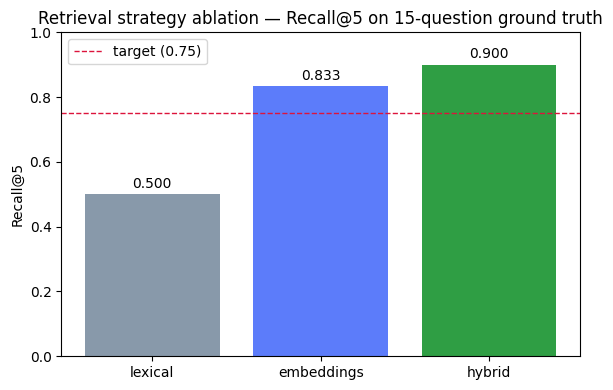

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(df.index, df["recall@5"], color=["#8899aa", "#5c7cfa", "#2f9e44"])
ax.axhline(0.75, color="crimson", linestyle="--", linewidth=1, label="target (0.75)")
ax.set_ylabel("Recall@5")
ax.set_title("Retrieval strategy ablation — Recall@5 on 15-question ground truth")
ax.set_ylim(0, 1.0)
for bar, val in zip(bars, df["recall@5"]):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.02, f"{val:.3f}", ha="center")
ax.legend()
fig.tight_layout()
fig.savefig("evaluation/results/ablation_retrieval_strategy.png", dpi=150)
plt.show()

## What the numbers mean

Plain TF-IDF cosine similarity is weak here (recall@5 ≈ 0.50) — legal Russian has heavy morphology that word-level TF-IDF doesn't normalize, and several ground-truth questions are paraphrased definitions that share little vocabulary with their source article. FAISS embeddings alone do much better (≈0.83). Weighted RRF of the two (≈0.90) beats either signal alone on *every* metric, including MRR and nDCG@10, not just recall@5.

These numbers reflect two fixes found in sequence, each caught by actually running the service, not by trusting the eval script alone (see `docs/adr/001-chunking.md` and `docs/adr/002-retrieval-fusion.md`):

1. **Chunking:** the first pass (chunking = one chunk per Статья/Пункт, no glossary splitting) got hybrid to only 0.767, with three definition questions failing under every backend because ПДД's glossary section packed dozens of unrelated terms into the same chunk. Splitting it by term (`split_glossary_by_term`) fixed all three — 0.767 → 0.967.
2. **RRF weighting:** that 0.967 used unweighted RRF over a `top_k`-scaled candidate pool. Manually asking the *live* service a realistic, colloquial question ("я выпил алкоголь за рулем, если остановят, то какие последствия?") returned a completely unrelated answer about overtaking rules — nowhere near the ground truth's formal phrasing, and not something this eval script would ever catch on its own. Root cause: TF-IDF found no vocabulary match for the colloquial query and ranked the correct chunk ~109th (real, but outside the 100-item pool); FAISS ranked it #1; but unweighted RRF let a chunk that was merely mediocre in *both* truncated signals outscore it. Fixed by ranking the full corpus (no pool truncation) and weighting embeddings 0.7 vs. lexical 0.3, since embeddings is the more reliable signal here on average. Ground-truth recall@5 dropped slightly, 0.967 → 0.900 (one definition question where lexical genuinely had the better answer regressed), but MRR and nDCG@10 both improved, and the colloquial query that was flatly broken now retrieves correctly.

The lesson worth remembering for defense: an offline eval number is only trustworthy if it's provably what the live endpoint returns, and a metric averaged over 15 ground-truth questions can hide a completely broken case that a differently-phrased real question exposes immediately. Both bugs here were found by manually querying the running service, not by the automated eval alone.

The one remaining gap is query 15 (recall 0.5) — a deliberately hard multi-chunk question spanning two different documents (ПДД §12 + КоАП Статья 608); one of its two expected chunks is retrieved, the other isn't. That's expected: each retrieval backend ranks chunks independently, so a question whose answer requires two chunks from different parts of the corpus is inherently harder than a single-chunk lookup, regardless of retrieval strategy.